# Bài tập lớn AS3179: khám phá dữ liệu (Mục 4.3)

Chỉ những gì cần cho mô hình: đồ thị chuỗi, ACF/PACF (tự cài đặt, `as3179ts.acf_tools`) và thống kê mô tả của 6 bộ dữ liệu đã làm sạch. Nguồn, đơn vị và các bước làm sạch: `data/DATA_SOURCES.md`. Phần nhận xét do nhóm viết (`TODO(nhóm)`).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import sys
import numpy as np, pandas as pd, scipy, statsmodels, matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats

from as3179ts.config import SEED
from as3179ts.data import load_processed
from as3179ts import acf_tools as A
from as3179ts.plotting import save_figure, show_figure, acf_bars, panel_label, BLUE, ORANGE, GREEN, RED, GREY
from as3179ts.reporting import save_table

print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__,
      "| statsmodels", statsmodels.__version__, "| matplotlib", matplotlib.__version__)
print("SEED =", SEED, "(notebook này không dùng số ngẫu nhiên)")
CODES = ("HU", "LY", "DR", "NI", "AP", "DP")
DATA = {c: load_processed(c) for c in CODES}
# (biến cần mô hình hóa, nhãn trục, cột thời gian)
SPEC = {"HU": ("level_ft", "mực nước (ft)", "year"), "LY": ("log10_count", "log10(số linh miêu)", "year"), "DR": ("ret_pct", "suất sinh lợi (%)", "t"),
        "NI": ("flow", "lưu lượng (10⁸ m³)", "year"), "AP": ("log_passengers", "log(hành khách)", "month"), "DP": ("log_close", "log DAX", "t")}
TIME = {"HU": DATA["HU"].year.to_numpy(), "LY": DATA["LY"].year.to_numpy(), "DR": DATA["DR"].t.to_numpy(), "NI": DATA["NI"].year.to_numpy(),
        "AP": 1949 + np.arange(144) / 12, "DP": DATA["DP"].t.to_numpy()}   # trục thời gian thật (AP: năm thập phân; DAX: ngày giao dịch)
XLAB = {"HU": "năm", "LY": "năm", "DR": "ngày giao dịch t", "NI": "năm", "AP": "năm", "DP": "ngày giao dịch t"}
TITLE = {"HU": "HU: mực nước hồ Huron", "LY": "LY: số linh miêu bị bẫy (log₁₀)", "DR": "DR: suất sinh lợi log ngày của DAX",
         "NI": "NI: lưu lượng sông Nile tại Aswan", "AP": "AP: số hành khách hàng không (log)", "DP": "DP: log giá đóng cửa DAX"}
pd.options.display.float_format = lambda v: f"{v:.4g}"

Python 3.12.14 | numpy 2.5.5 | pandas 3.1.1 | scipy 1.18.1 | statsmodels 0.15.0 | matplotlib 3.11.2
SEED = 3179 (notebook này không dùng số ngẫu nhiên)


## Thống kê mô tả

In [2]:
rows = []
for c in CODES:
    col, _, tcol = SPEC[c]; v = DATA[c][col].to_numpy(); t = DATA[c][tcol]
    rows.append({"bộ": c, "biến": col, "n": len(v), "từ": t.iloc[0], "đến": t.iloc[-1], "trung bình": v.mean(), "SD": v.std(ddof=1),
                 "min": v.min(), "max": v.max(), "độ lệch": stats.skew(v), "kurtosis dư": stats.kurtosis(v)})
tab_desc = save_table(pd.DataFrame(rows).set_index("bộ"), "tab_eda_descriptive")

In [3]:
tab_desc

,biến,n,từ,đến,trung bình,SD,min,max,độ lệch,kurtosis dư
bộ,,,,,,,,,,
HU,level_ft,98,1875,1972,579,1.318,576,581.9,-0.1398,-0.5008
LY,log10_count,114,1821,1934,2.904,0.5584,1.591,3.845,-0.362,-0.7336
DR,ret_pct,1859,2,1860,0.0652,1.03,-9.628,5.076,-0.5541,6.28
NI,flow,100,1871,1970,919.4,169.2,456,1370,0.3224,-0.3049
AP,log_passengers,144,1949-01,1960-12,5.542,0.4415,4.644,6.433,-0.1207,-0.9721
DP,log_close,1860,1,1860,7.763,0.3632,7.246,8.73,0.9338,-0.03828


## HU

Mực nước hồ Huron 1875–1972 (Bài 11, ví dụ (i)); đường gạch là xu thế tuyến tính OLS theo $x=$ năm $-1920$.

In [4]:
CODE = "HU"
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.9), gridspec_kw={"width_ratios": [1.6, 1, 1]}); y = DATA[CODE][SPEC[CODE][0]].to_numpy(); n = len(y); tt = TIME[CODE]
axes[0].plot(tt, y, lw=0.9, color=BLUE); axes[0].set(title=TITLE[CODE], xlabel=XLAB[CODE], ylabel=SPEC[CODE][1])
x = DATA["HU"].x_centered.to_numpy(float); axes[0].plot(tt, np.polyval(np.polyfit(x, y, 1), x), color=RED, ls="--", lw=1.6, label="xu thế tuyến tính (OLS)"); axes[0].legend(loc="upper right")
acf_bars(axes[1], A.sample_acf(y, 30), n, f"{CODE}: ACF mẫu", ylabel="ACF"); acf_bars(axes[2], A.pacf_durbin_levinson(A.sample_acf(y, 30), 30), n, f"{CODE}: PACF mẫu", ylabel="PACF")
for k, ax in enumerate(axes): panel_label(ax, "(" + "abc"[k] + ")")
fig_path = save_figure(fig, f"fig_eda_{CODE}_overview")

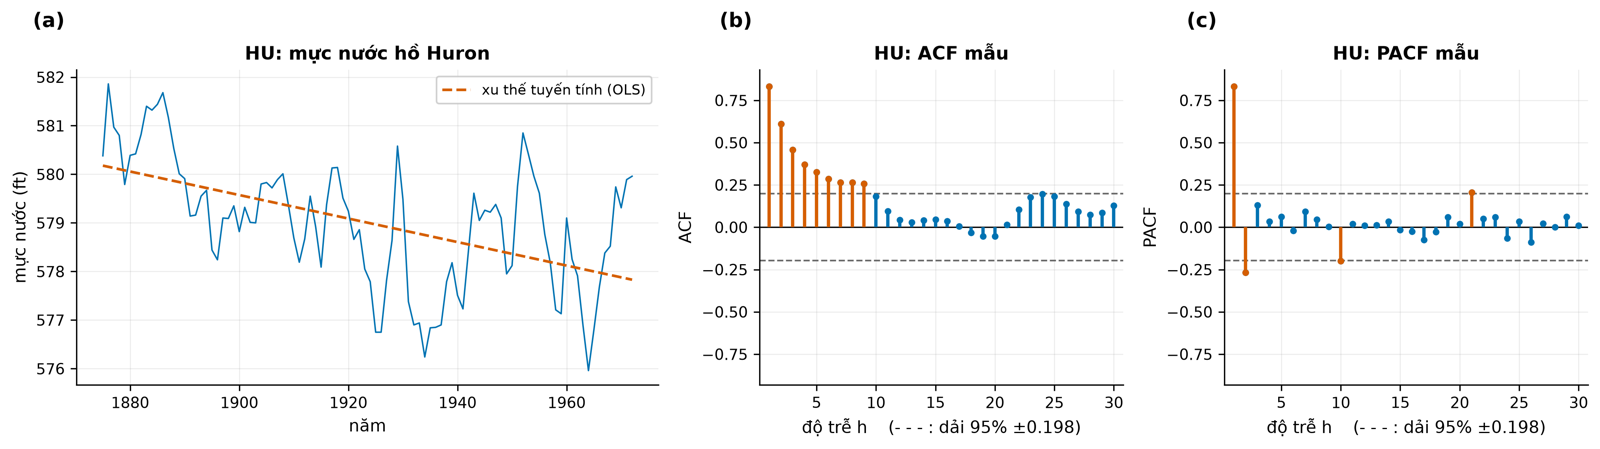

In [5]:
show_figure(fig_path)

**TODO(nhóm):** nhận xét ngắn về HU: xu thế/mùa vụ/phương sai có đổi theo thời gian không, ACF/PACF gợi ý điều gì cho mô hình ở Bài 11–12?

## LY

Số linh miêu bị bẫy hằng năm, $y=\log_{10}$(số lượng) (Bài 11, ví dụ (ii)); chu kỳ ≈ 10 năm.

In [6]:
CODE = "LY"
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.9), gridspec_kw={"width_ratios": [1.6, 1, 1]}); y = DATA[CODE][SPEC[CODE][0]].to_numpy(); n = len(y); tt = TIME[CODE]
axes[0].plot(tt, y, lw=0.9, color=BLUE); axes[0].set(title=TITLE[CODE], xlabel=XLAB[CODE], ylabel=SPEC[CODE][1])

acf_bars(axes[1], A.sample_acf(y, 30), n, f"{CODE}: ACF mẫu", ylabel="ACF"); acf_bars(axes[2], A.pacf_durbin_levinson(A.sample_acf(y, 30), 30), n, f"{CODE}: PACF mẫu", ylabel="PACF")
for k, ax in enumerate(axes): panel_label(ax, "(" + "abc"[k] + ")")
fig_path = save_figure(fig, f"fig_eda_{CODE}_overview")

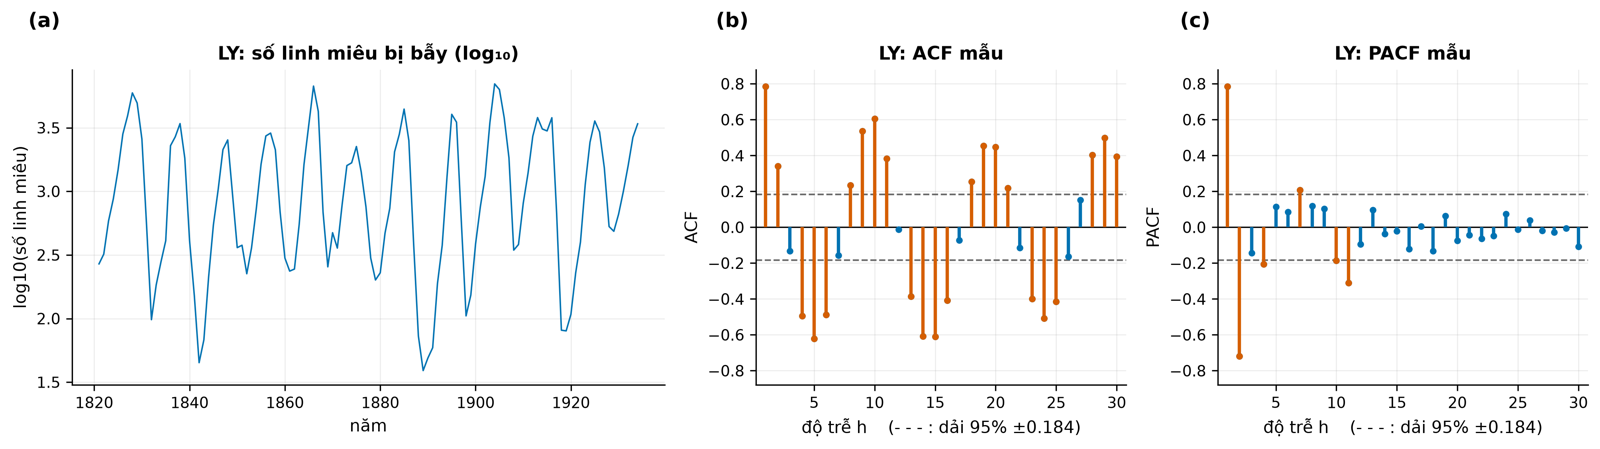

In [7]:
show_figure(fig_path)

**TODO(nhóm):** nhận xét ngắn về LY: xu thế/mùa vụ/phương sai có đổi theo thời gian không, ACF/PACF gợi ý điều gì cho mô hình ở Bài 11–12?

## DR

Suất sinh lợi log của DAX $r_t=100\,\Delta\log P_t$ (Bài 11, ví dụ (iii)); chỉ số $t$ là ngày giao dịch, **không có ngày lịch**.

In [8]:
CODE = "DR"
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.9), gridspec_kw={"width_ratios": [1.6, 1, 1]}); y = DATA[CODE][SPEC[CODE][0]].to_numpy(); n = len(y); tt = TIME[CODE]
axes[0].plot(tt, y, lw=0.9, color=BLUE); axes[0].set(title=TITLE[CODE], xlabel=XLAB[CODE], ylabel=SPEC[CODE][1])
axes[0].axhline(0, color="k", lw=0.6)
acf_bars(axes[1], A.sample_acf(y, 30), n, f"{CODE}: ACF mẫu", ylabel="ACF"); acf_bars(axes[2], A.pacf_durbin_levinson(A.sample_acf(y, 30), 30), n, f"{CODE}: PACF mẫu", ylabel="PACF")
for k, ax in enumerate(axes): panel_label(ax, "(" + "abc"[k] + ")")
fig_path = save_figure(fig, f"fig_eda_{CODE}_overview")

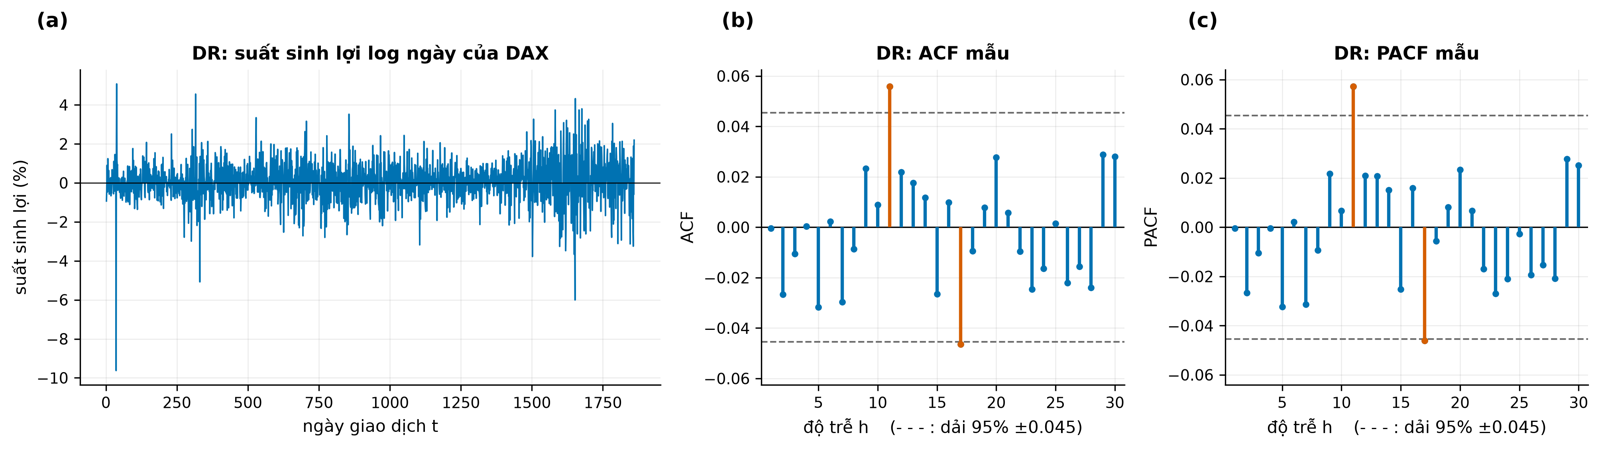

In [9]:
show_figure(fig_path)

**TODO(nhóm):** nhận xét ngắn về DR: xu thế/mùa vụ/phương sai có đổi theo thời gian không, ACF/PACF gợi ý điều gì cho mô hình ở Bài 11–12?

## NI

Lưu lượng sông Nile tại Aswan 1871–1970 (Bài 12, ví dụ (i)); đường đỏ là trung bình trước/sau 1899.

In [10]:
CODE = "NI"
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.9), gridspec_kw={"width_ratios": [1.6, 1, 1]}); y = DATA[CODE][SPEC[CODE][0]].to_numpy(); n = len(y); tt = TIME[CODE]
axes[0].plot(tt, y, lw=0.9, color=BLUE); axes[0].set(title=TITLE[CODE], xlabel=XLAB[CODE], ylabel=SPEC[CODE][1])
m1, m2 = y[tt < 1899].mean(), y[tt >= 1899].mean(); axes[0].axvline(1899, color=GREY, ls="--", lw=1.2); axes[0].hlines([m1, m2], [tt[0], 1899], [1899, tt[-1]], color=RED, lw=1.8, label=f"trung bình {m1:.0f} (trước 1899) và {m2:.0f} (từ 1899)"); axes[0].legend(loc="upper right", fontsize=8)
acf_bars(axes[1], A.sample_acf(y, 30), n, f"{CODE}: ACF mẫu", ylabel="ACF"); acf_bars(axes[2], A.pacf_durbin_levinson(A.sample_acf(y, 30), 30), n, f"{CODE}: PACF mẫu", ylabel="PACF")
for k, ax in enumerate(axes): panel_label(ax, "(" + "abc"[k] + ")")
fig_path = save_figure(fig, f"fig_eda_{CODE}_overview")

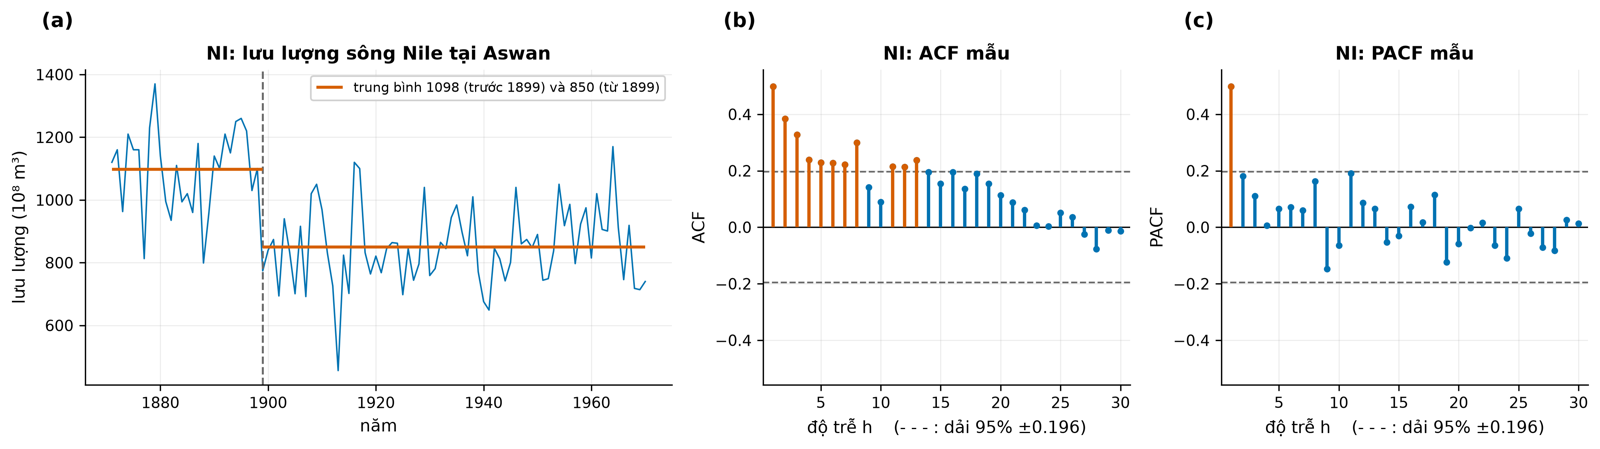

In [11]:
show_figure(fig_path)

**TODO(nhóm):** nhận xét ngắn về NI: xu thế/mùa vụ/phương sai có đổi theo thời gian không, ACF/PACF gợi ý điều gì cho mô hình ở Bài 11–12?

## AP

Hành khách hàng không, $\log$ (Bài 12, ví dụ (ii)); 120 tháng huấn luyện | 24 tháng kiểm định.

In [12]:
CODE = "AP"
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.9), gridspec_kw={"width_ratios": [1.6, 1, 1]}); y = DATA[CODE][SPEC[CODE][0]].to_numpy(); n = len(y); tt = TIME[CODE]
axes[0].plot(tt, y, lw=0.9, color=BLUE); axes[0].set(title=TITLE[CODE], xlabel=XLAB[CODE], ylabel=SPEC[CODE][1])
axes[0].axvline(1959, color=GREY, ls="--", lw=1.2); axes[0].text(1959.1, axes[0].get_ylim()[0] + 0.05, "kiểm định →", fontsize=8, color=GREY); axes[0].text(1958.9, axes[0].get_ylim()[0] + 0.05, "← huấn luyện", fontsize=8, color=GREY, ha="right")
acf_bars(axes[1], A.sample_acf(y, 30), n, f"{CODE}: ACF mẫu", ylabel="ACF"); acf_bars(axes[2], A.pacf_durbin_levinson(A.sample_acf(y, 30), 30), n, f"{CODE}: PACF mẫu", ylabel="PACF")
for k, ax in enumerate(axes): panel_label(ax, "(" + "abc"[k] + ")")
fig_path = save_figure(fig, f"fig_eda_{CODE}_overview")

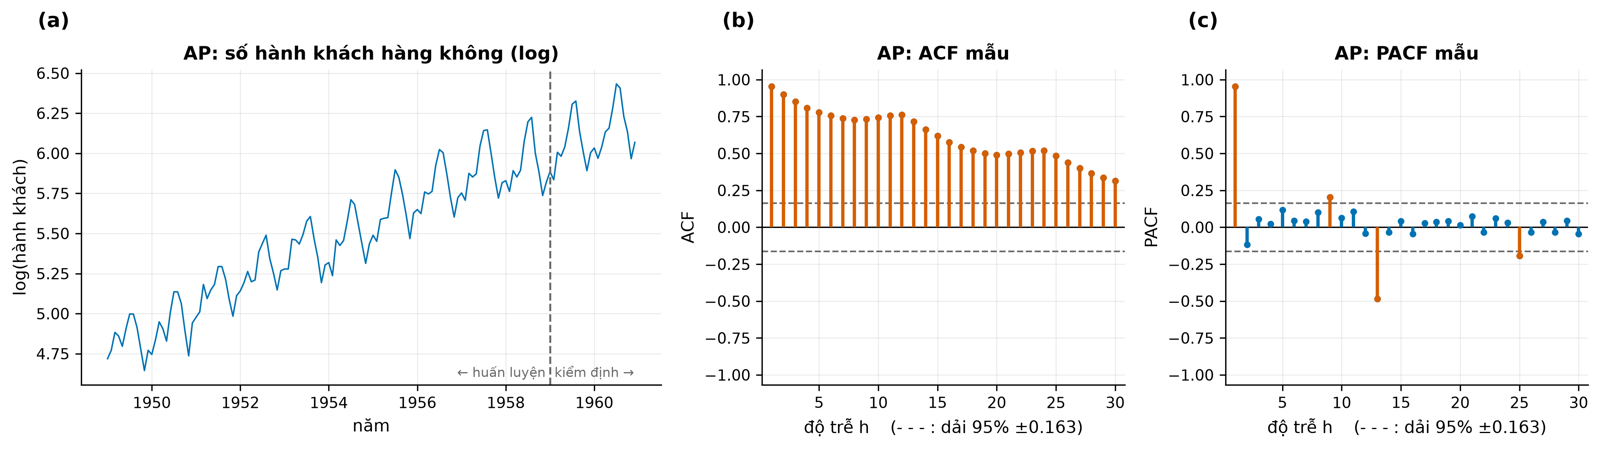

In [13]:
show_figure(fig_path)

**TODO(nhóm):** nhận xét ngắn về AP: xu thế/mùa vụ/phương sai có đổi theo thời gian không, ACF/PACF gợi ý điều gì cho mô hình ở Bài 11–12?

## DP

Log giá đóng cửa DAX (Bài 12, ví dụ (iii)); 1500 ngày huấn luyện | 360 ngày kiểm định; chỉ số ngày giao dịch.

In [14]:
CODE = "DP"
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.9), gridspec_kw={"width_ratios": [1.6, 1, 1]}); y = DATA[CODE][SPEC[CODE][0]].to_numpy(); n = len(y); tt = TIME[CODE]
axes[0].plot(tt, y, lw=0.9, color=BLUE); axes[0].set(title=TITLE[CODE], xlabel=XLAB[CODE], ylabel=SPEC[CODE][1])
axes[0].axvline(1500, color=GREY, ls="--", lw=1.2); axes[0].text(1520, axes[0].get_ylim()[0] + 0.05, "kiểm định →", fontsize=8, color=GREY); axes[0].text(1480, axes[0].get_ylim()[0] + 0.05, "← huấn luyện", fontsize=8, color=GREY, ha="right")
acf_bars(axes[1], A.sample_acf(y, 30), n, f"{CODE}: ACF mẫu", ylabel="ACF"); acf_bars(axes[2], A.pacf_durbin_levinson(A.sample_acf(y, 30), 30), n, f"{CODE}: PACF mẫu", ylabel="PACF")
for k, ax in enumerate(axes): panel_label(ax, "(" + "abc"[k] + ")")
fig_path = save_figure(fig, f"fig_eda_{CODE}_overview")

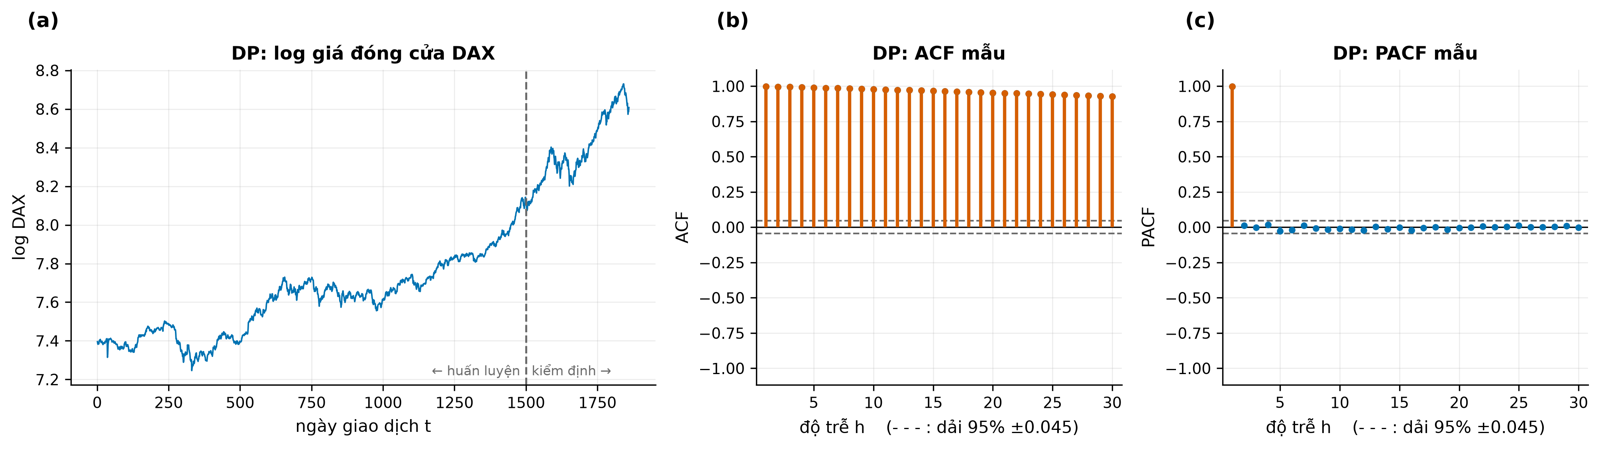

In [15]:
show_figure(fig_path)

**TODO(nhóm):** nhận xét ngắn về DP: xu thế/mùa vụ/phương sai có đổi theo thời gian không, ACF/PACF gợi ý điều gì cho mô hình ở Bài 11–12?